# Wind Energy Potential Assessment using ERA5-WRF Dataset

This notebook demonstrates a practical use case: assessing **wind energy potential** for a location using the ERA5-WRF global timeseries data available on AWS.

## Use Case
Wind farm developers and energy planners need to understand wind patterns at potential sites. This analysis:
- Downloads historical wind data for a location
- Analyzes wind speed distribution and patterns
- Estimates energy production potential (with air-density correction)
- Visualizes wind direction frequency and energy

## Dataset
We use the **Global Timeseries** product from ERA5-WRF, which provides:
- 100-m wind speed and direction (ideal for modern wind turbines)
- Hourly resolution from 2000 to present
- 0.25° global grid (~28 km resolution)


In [1]:
# Install required packages if needed
# !pip install boto3 pandas numpy matplotlib scipy -q


In [2]:
import boto3
from botocore import UNSIGNED
from botocore.config import Config
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display


## 1. Define Location and Find Grid Cell

The ERA5-WRF timeseries data is organized by grid cell IDs. We need to find the grid cell corresponding to our location of interest.

Let's analyze a location in **West Texas** - a region known for excellent wind resources.


In [3]:
# Target location: West Texas (near Sweetwater - major wind farm area)
TARGET_LAT = 32.5
TARGET_LON = -100.5
LOCATION_NAME = "West Texas"
LOCAL_TZ = "America/Chicago"  # for diurnal plot

# S3 configuration (no credentials needed - public bucket)
s3 = boto3.client('s3', config=Config(signature_version=UNSIGNED), region_name='us-east-1')
BUCKET = 'era5-for-wrf'


In [4]:
# Download the grid cell mapping file
print("Downloading grid cell mapping...")
response = s3.get_object(Bucket=BUCKET, Key='era5_global_gids.csv')
gids_df = pd.read_csv(response['Body'])
print(f"Grid mapping loaded: {len(gids_df)} cells")
gids_df.head()


Grid mapping loaded: 1038240 cells


,Unnamed: 0,gid,lat,lon
0,0,1,90.0,0.00
1,1,2,90.0,0.25
2,2,3,90.0,0.50
3,3,4,90.0,0.75
4,4,5,90.0,1.00


In [5]:
# Find the nearest grid cell to our target location.
# Uses haversine distance so results are correct away from the equator,
# and pre-filters by a small lat/lon bounding box for speed.
EARTH_R_KM = 6371.0

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between two points (vectorized)."""
    lat1r, lat2r = np.radians(lat1), np.radians(lat2)
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1r) * np.cos(lat2r) * np.sin(dlon / 2) ** 2
    return 2 * EARTH_R_KM * np.arcsin(np.sqrt(a))

def find_nearest_cell(df, lat, lon, search_radius_deg=1.0):
    """Find the grid cell closest to (lat, lon) using haversine distance."""
    # Bounding-box filter (cheap) before computing haversine on every row.
    mask = (
        (df['lat'].between(lat - search_radius_deg, lat + search_radius_deg))
        & (df['lon'].between(lon - search_radius_deg, lon + search_radius_deg))
    )
    candidates = df[mask]
    if candidates.empty:
        candidates = df  # fall back to full search if box is empty
    distances = haversine_km(lat, lon, candidates['lat'].values, candidates['lon'].values)
    return candidates.iloc[int(np.argmin(distances))]

nearest = find_nearest_cell(gids_df, TARGET_LAT, TARGET_LON)
grid_id = int(nearest['gid'])
print(f"Target: ({TARGET_LAT}, {TARGET_LON})")
print(f"Nearest grid cell: ID={grid_id}, Lat={nearest['lat']}, Lon={nearest['lon']}")


Target: (32.5, -100.5)
Nearest grid cell: ID=332239, Lat=32.5, Lon=-100.5


## 2. Download Wind Data


In [6]:
# Download timeseries data for our grid cell.
# Grid IDs are zero-padded to 7 digits in the S3 path.
key = f'global_single_level/cells/{grid_id:07d}/timeseries.csv'
print(f"Downloading timeseries from: s3://{BUCKET}/{key}")

response = s3.get_object(Bucket=BUCKET, Key=key)

# The CSV has a metadata row first, then headers, then data:
#   Line 0: "gid = X, lat = Y, lon = Z"
#   Line 1: column headers
#   Line 2+: data
df = pd.read_csv(response['Body'], skiprows=1, parse_dates=['datetime'])
df.set_index('datetime', inplace=True)

# Rename columns to friendlier names
df.columns = ['wind_speed_100m', 'wind_direction_100m', 'temperature_2m', 'surface_pressure']

print(f"\nData downloaded: {len(df)} hourly records")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"\nMissing values per column:")
print(df.isna().sum())
df.head()



Data downloaded: 214032 hourly records
Date range: 2000-01-01 00:00:00 to 2024-04-30 23:00:00

Missing values per column:
wind_speed_100m        0
wind_direction_100m    0
temperature_2m         0
surface_pressure       0
dtype: int64


,wind_speed_100m,wind_direction_100m,temperature_2m,surface_pressure
datetime,,,,
2000-01-01 00:00:00,5.88,185.42,288.83,93466.43
2000-01-01 01:00:00,7.52,179.04,289.37,93457.09
2000-01-01 02:00:00,8.66,175.23,288.67,93444.48
2000-01-01 03:00:00,9.38,173.95,284.40,93444.27
2000-01-01 04:00:00,10.10,176.29,284.70,93421.05


In [7]:
# Quick statistics
print("Wind Speed Statistics (100m height):")
print(f"  Mean: {df['wind_speed_100m'].mean():.2f} m/s")
print(f"  Std:  {df['wind_speed_100m'].std():.2f} m/s")
print(f"  Min:  {df['wind_speed_100m'].min():.2f} m/s")
print(f"  Max:  {df['wind_speed_100m'].max():.2f} m/s")


Wind Speed Statistics (100m height):
  Mean: 7.60 m/s
  Std:  3.18 m/s
  Min:  0.00 m/s
  Max:  23.28 m/s


## 3. Wind Speed Distribution Analysis

Wind speeds typically follow a **Weibull distribution**, which is essential for energy yield calculations.


In [8]:
# Fit Weibull distribution to wind speed data
wind_speeds = df['wind_speed_100m'].dropna().values

# Weibull fit (shape=k, scale=A); location forced to 0 since wind speed is non-negative.
shape, _loc, scale = stats.weibull_min.fit(wind_speeds, floc=0)
print("Weibull Parameters:")
print(f"  Shape (k): {shape:.2f}")
print(f"  Scale (A): {scale:.2f} m/s")


Weibull Parameters:
  Shape (k): 2.56
  Scale (A): 8.55 m/s


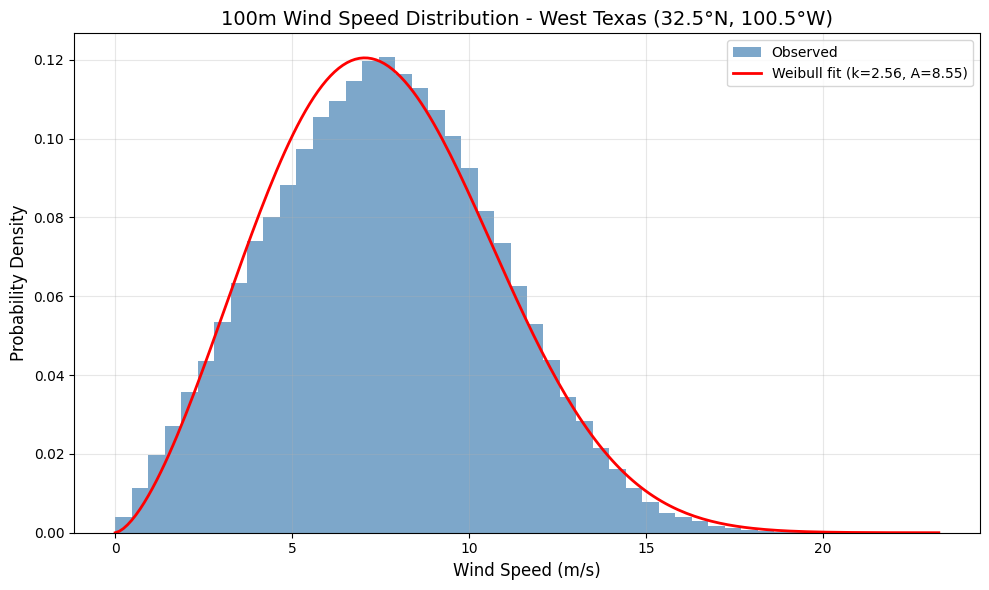

In [9]:
# Plot wind speed distribution
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(wind_speeds, bins=50, density=True, alpha=0.7, label='Observed', color='steelblue')

x = np.linspace(0, wind_speeds.max(), 200)
weibull_pdf = stats.weibull_min.pdf(x, shape, loc=0, scale=scale)
ax.plot(x, weibull_pdf, 'r-', lw=2, label=f'Weibull fit (k={shape:.2f}, A={scale:.2f})')

ax.set_xlabel('Wind Speed (m/s)', fontsize=12)
ax.set_ylabel('Probability Density', fontsize=12)
ax.set_title(
    f'100m Wind Speed Distribution - {LOCATION_NAME} ({TARGET_LAT}°N, {abs(TARGET_LON)}°W)',
    fontsize=14,
)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 4. Temporal Patterns Analysis

Understanding when wind blows is crucial for grid integration and energy planning. The diurnal plot is shown in **local time** for interpretability.


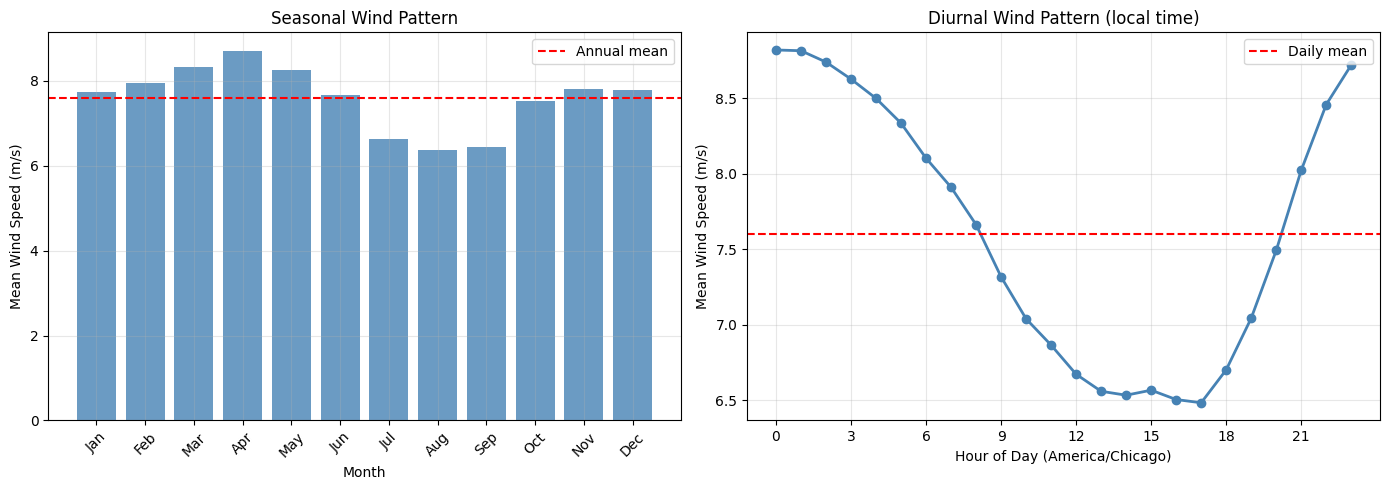

In [10]:
# Build a local-time view for the diurnal plot.
df_local = df.copy()
df_local.index = df_local.index.tz_localize('UTC').tz_convert(LOCAL_TZ)

monthly_avg = df['wind_speed_100m'].groupby(df.index.month).mean()
hourly_avg_local = df_local['wind_speed_100m'].groupby(df_local.index.hour).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[0].bar(range(1, 13), monthly_avg.values, color='steelblue', alpha=0.8)
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(months, rotation=45)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Mean Wind Speed (m/s)')
axes[0].set_title('Seasonal Wind Pattern')
axes[0].axhline(y=df['wind_speed_100m'].mean(), color='red', linestyle='--', label='Annual mean')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(hourly_avg_local.index, hourly_avg_local.values, 'o-',
             color='steelblue', lw=2, markersize=6)
axes[1].set_xlabel(f'Hour of Day ({LOCAL_TZ})')
axes[1].set_ylabel('Mean Wind Speed (m/s)')
axes[1].set_title('Diurnal Wind Pattern (local time)')
axes[1].set_xticks(range(0, 24, 3))
axes[1].axhline(y=df['wind_speed_100m'].mean(), color='red', linestyle='--', label='Daily mean')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Wind Energy Estimation

We estimate energy production using a simplified turbine power curve and apply an **air-density correction** since power scales linearly with density: $P \propto \rho$.

Air density is derived from temperature and surface pressure via the ideal gas law:
$$\rho = \frac{p}{R_d \, T}$$
where $R_d = 287.05\,\mathrm{J\,kg^{-1}\,K^{-1}}$ for dry air.


In [11]:
# Simplified power curve for a typical 3 MW wind turbine
def turbine_power(wind_speed, rated_power=3000, cut_in=3.5, rated_speed=12, cut_out=25):
    """
    Simplified power curve (kW output for given wind speed in m/s).
    - cut_in: minimum wind speed for power generation
    - rated_speed: wind speed at which rated power is reached
    - cut_out: maximum operating wind speed
    """
    wind_speed = np.asarray(wind_speed, dtype=float)
    power = np.zeros_like(wind_speed, dtype=float)

    # Between cut-in and rated: cubic ramp
    mask_ramp = (wind_speed >= cut_in) & (wind_speed < rated_speed)
    power[mask_ramp] = rated_power * (
        (wind_speed[mask_ramp] - cut_in) / (rated_speed - cut_in)
    ) ** 3

    # Between rated and cut-out: rated power
    mask_rated = (wind_speed >= rated_speed) & (wind_speed <= cut_out)
    power[mask_rated] = rated_power

    return power

# Air density (kg/m^3) from ideal gas law for dry air.
R_DRY_AIR = 287.05  # J/(kg*K)
RHO_REF = 1.225     # kg/m^3, ISA sea-level reference

df['air_density'] = df['surface_pressure'] / (R_DRY_AIR * df['temperature_2m'])

# Density correction (IEC 61400-12 method): apply to the *wind speed* rather than
# scaling the output power. Power below rated scales with density, and because the
# effective speed is fed through the power curve, the flat rated-power plateau is
# preserved (real turbines pitch to hold rated power regardless of air density).
#   v_eff = v * (rho / rho_ref) ** (1/3)
density_ratio = df['air_density'] / RHO_REF
effective_wind = df['wind_speed_100m'] * density_ratio ** (1.0 / 3.0)
df['power_kw'] = turbine_power(effective_wind.values)

print(f"Mean air density: {df['air_density'].mean():.3f} kg/m³ "
      f"(reference: {RHO_REF} kg/m³)")


Mean air density: 1.120 kg/m³ (reference: 1.225 kg/m³)


In [12]:
# Calculate key metrics
RATED_POWER_KW = 3000
HOURS_PER_YEAR = 8760

# The record ends partway through a year (Jan-Apr are over-represented), and those
# are the windiest months in West Texas. A plain mean over every hour would bias the
# headline numbers high. To remove that bias we first average within each calendar
# month, then weight those monthly means by calendar-month length so every month
# contributes its true share of a representative year.
DAYS_IN_MONTH = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

def annual_weighted_mean(series):
    """Mean that weights each calendar month by its length (removes partial-year bias)."""
    monthly = series.groupby(series.index.month).mean()
    weights = DAYS_IN_MONTH[monthly.index.values - 1]
    return np.average(monthly.values, weights=weights)

mean_wind = annual_weighted_mean(df['wind_speed_100m'])
mean_power_kw = annual_weighted_mean(df['power_kw'])
capacity_factor = mean_power_kw / RATED_POWER_KW
annual_energy_mwh = mean_power_kw * HOURS_PER_YEAR / 1000
equivalent_full_hours = capacity_factor * HOURS_PER_YEAR
n_years = df.index.year.nunique()

print("=" * 50)
print("WIND ENERGY POTENTIAL SUMMARY")
print("=" * 50)
print(f"Location: {TARGET_LAT}°N, {abs(TARGET_LON)}°W ({LOCATION_NAME})")
print(f"Data period: {df.index.min().year} - {df.index.max().year}")
print(f"\nWind Resource:")
print(f"  Mean wind speed (100m): {mean_wind:.2f} m/s")
print(f"  Weibull shape (k):      {shape:.2f}")
print(f"  Weibull scale (A):      {scale:.2f} m/s")
print(f"\nEnergy Production (3 MW turbine, density-corrected):")
print(f"  Capacity Factor:        {capacity_factor*100:.1f}%")
print(f"  Annual Energy:          {annual_energy_mwh:,.0f} MWh/year")
print(f"  Equivalent Full Hours:  {equivalent_full_hours:,.0f} hours/year")
print("=" * 50)


WIND ENERGY POTENTIAL SUMMARY
Location: 32.5°N, 100.5°W (West Texas)
Data period: 2000 - 2024

Wind Resource:
  Mean wind speed (100m): 7.60 m/s
  Weibull shape (k):      2.56
  Weibull scale (A):      8.55 m/s

Energy Production (3 MW turbine, density-corrected):
  Capacity Factor:        23.8%
  Annual Energy:          6,243 MWh/year
  Equivalent Full Hours:  2,081 hours/year


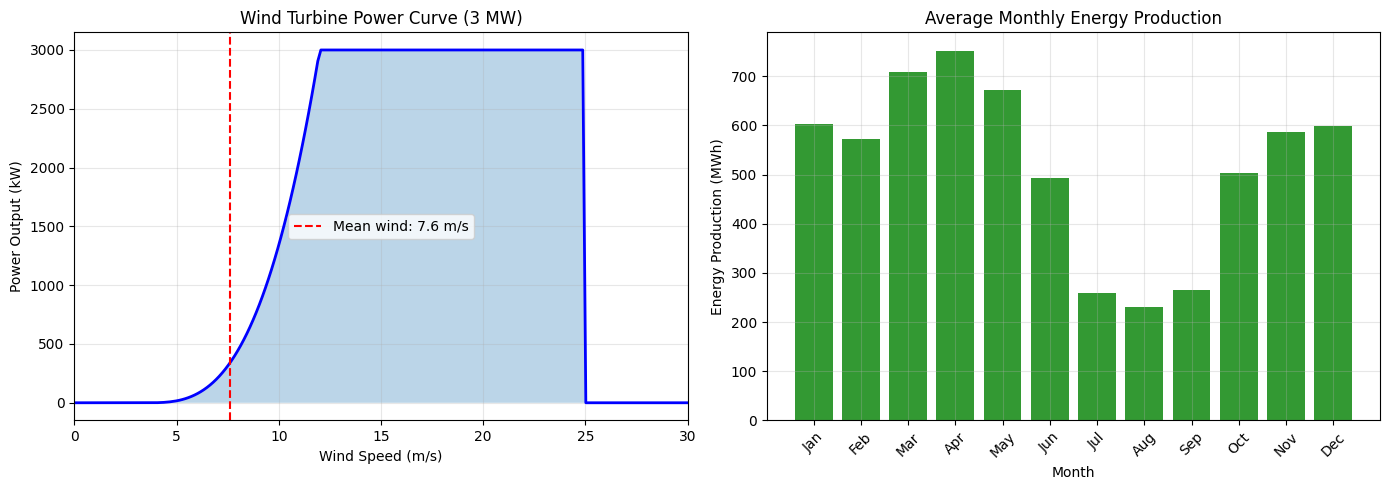

In [13]:
# Visualize the power curve and production distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Power curve (uncorrected, for shape illustration)
ws_range = np.linspace(0, 30, 200)
power_curve = turbine_power(ws_range)
axes[0].plot(ws_range, power_curve, 'b-', lw=2)
axes[0].axvline(x=mean_wind, color='red', linestyle='--',
                label=f'Mean wind: {mean_wind:.1f} m/s')
axes[0].fill_between(ws_range, power_curve, alpha=0.3)
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Power Output (kW)')
axes[0].set_title('Wind Turbine Power Curve (3 MW)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(0, 30)

# Average MWh produced in a typical calendar month:
#   mean power (kW) for that month  x  hours in that month  / 1000.
# Using the per-month mean kW (rather than summing energy and dividing by a single
# year count) avoids bias from Jan-Apr appearing in one more year than May-Dec.
mean_kw_per_month = df['power_kw'].groupby(df.index.month).mean()
hours_in_month = DAYS_IN_MONTH[mean_kw_per_month.index.values - 1] * 24
monthly_energy_mwh = mean_kw_per_month * hours_in_month / 1000

axes[1].bar(range(1, 13), monthly_energy_mwh.values, color='green', alpha=0.8)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(months, rotation=45)
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Energy Production (MWh)')
axes[1].set_title('Average Monthly Energy Production')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Wind Rose (Direction Analysis)

Two roses are shown:
- **Frequency rose**: how often wind blows from each direction.
- **Energy rose**: weighted by $v^3$ (proportional to wind power), showing where the energy actually comes from.


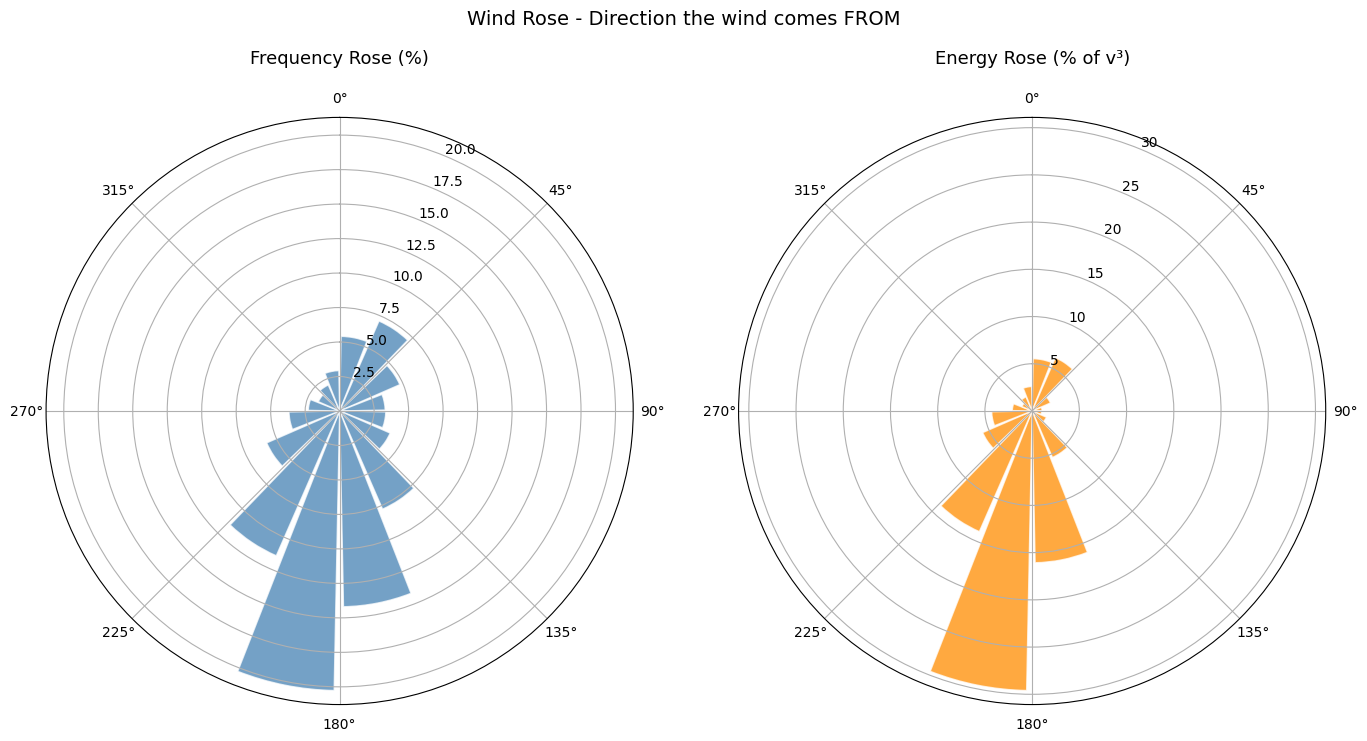

Predominant wind direction:    191° (20.3% of time)
Predominant energy direction:  191° (29.6% of energy)


In [14]:
# Build wind roses. Use 16 sectors and meteorological convention
# (0° = wind FROM north, increasing clockwise).
n_sectors = 16
dir_bins = np.linspace(0, 360, n_sectors + 1)
dir_centers = (dir_bins[:-1] + dir_bins[1:]) / 2

valid = df[['wind_direction_100m', 'wind_speed_100m']].dropna()
wind_dir = valid['wind_direction_100m'].values
wind_spd = valid['wind_speed_100m'].values

# Frequency rose
dir_counts, _ = np.histogram(wind_dir, bins=dir_bins)
dir_freq = dir_counts / len(wind_dir) * 100

# Energy rose (weight by v^3, then normalize to a percentage)
energy_weights = wind_spd ** 3
energy_per_bin, _ = np.histogram(wind_dir, bins=dir_bins, weights=energy_weights)
energy_pct = energy_per_bin / energy_per_bin.sum() * 100

# Convert sector centers (degrees, compass) directly to radians.
# We rely on set_theta_zero_location('N') + set_theta_direction(-1) to handle
# the compass-vs-math convention - no extra (90 - x) flip.
theta = np.radians(dir_centers)
width = 2 * np.pi / n_sectors * 0.9

fig, axes = plt.subplots(1, 2, figsize=(14, 7), subplot_kw={'projection': 'polar'})

for ax, values, title, color in [
    (axes[0], dir_freq, 'Frequency Rose (%)', 'steelblue'),
    (axes[1], energy_pct, 'Energy Rose (% of v³)', 'darkorange'),
]:
    ax.bar(theta, values, width=width, alpha=0.75, color=color, edgecolor='white')
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)  # clockwise, like a compass
    ax.set_title(title, pad=20, fontsize=13)

plt.suptitle('Wind Rose - Direction the wind comes FROM', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

predominant_idx = int(np.argmax(dir_freq))
energy_idx = int(np.argmax(energy_pct))
predominant_dir = dir_centers[predominant_idx]
energy_dir = dir_centers[energy_idx]
print(f"Predominant wind direction:    {predominant_dir:.0f}° "
      f"({dir_freq[predominant_idx]:.1f}% of time)")
print(f"Predominant energy direction:  {energy_dir:.0f}° "
      f"({energy_pct[energy_idx]:.1f}% of energy)")


## Site Assessment Summary

The summary below is generated from the metrics computed above, so it stays accurate when you change the target location.


In [15]:
def assess(label, value, good, very_good, fmt="{:.2f}", unit=""):
    if value >= very_good:
        verdict = "**Excellent**"
    elif value >= good:
        verdict = "**Good**"
    else:
        verdict = "Marginal"
    return f"| {label} | {fmt.format(value)}{unit} | {verdict} |"

rows = [
    assess("Mean Wind Speed (100m)", mean_wind, good=6.5, very_good=7.5, fmt="{:.2f}", unit=" m/s"),
    assess("Capacity Factor",        capacity_factor * 100, good=25, very_good=35, fmt="{:.1f}", unit="%"),
    assess("Weibull Shape (k)",      shape, good=1.8, very_good=2.3, fmt="{:.2f}"),
]
energy_row = f"| Annual Energy (3 MW) | {annual_energy_mwh:,.0f} MWh | - |"

summary = f"""
### Site: {LOCATION_NAME} ({TARGET_LAT}°N, {abs(TARGET_LON)}°W)

Based on {n_years} years of ERA5 reanalysis data ({df.index.min().year}-{df.index.max().year}):

| Metric | Value | Assessment |
|--------|-------|------------|
{rows[0]}
{rows[1]}
{rows[2]}
{energy_row}

- Predominant wind direction (frequency): **{predominant_dir:.0f}°** ({dir_freq[predominant_idx]:.1f}% of time)
- Predominant energy direction: **{energy_dir:.0f}°** ({energy_pct[energy_idx]:.1f}% of energy)
- Mean air density: **{df['air_density'].mean():.3f} kg/m³**
"""

display(Markdown(summary))



### Site: West Texas (32.5°N, 100.5°W)

Based on 25 years of ERA5 reanalysis data (2000-2024):

| Metric | Value | Assessment |
|--------|-------|------------|
| Mean Wind Speed (100m) | 7.60 m/s | **Excellent** |
| Capacity Factor | 23.8% | Marginal |
| Weibull Shape (k) | 2.56 | **Excellent** |
| Annual Energy (3 MW) | 6,243 MWh | - |

- Predominant wind direction (frequency): **191°** (20.3% of time)
- Predominant energy direction: **191°** (29.6% of energy)
- Mean air density: **1.120 kg/m³**


## Conclusion

This analysis demonstrates how the ERA5-WRF dataset can be used for **preliminary wind energy assessments**:

1. **Easy access**: The S3-hosted data requires no authentication and is well organized by grid cell.
2. **Relevant variables**: 100m wind speed matches modern turbine hub heights; temperature and pressure enable air-density correction.
3. **Long time series**: 24+ years of hourly data enables robust statistical analysis.
4. **Global coverage**: Any location worldwide at 0.25° resolution.

### Practical Applications
- **Site prospecting**: compare multiple locations for wind farm development.
- **Grid planning**: understand seasonal and diurnal patterns for dispatch.
- **Financial modeling**: estimate energy revenues for project financing.
- **Validation**: compare with on-site measurements or other reanalysis products.

### Limitations
- Reanalysis data is modeled, not measured (site validation still needed).
- 0.25° resolution may not capture local terrain effects.
- Power curve is simplified; real turbines have more complex behavior.
- Density correction uses 2-m temperature as a proxy; a hub-height extrapolation would be more accurate.
